# 🚨 13. Clasificación: alerta de caída fuerte

Los 112 modelos de clasificación (7 modelos × 4 balanceos × 4 optimizadores) predicen si mañana un negocio tendrá una **caída fuerte** (venta < 50 % de la mediana de su semana anterior; 3,7 % de los casos en train). La métrica de validación es el **F1 de la clase caída** (cap. 9.6).

Orden del capítulo: métricas del bucle externo → efecto del balanceo → el mejor de cada modelo en test (matriz de confusión, ROC, tabla de métricas) → calibración → comparación estadística (Friedman → Nemenyi → DeLong → tamaño del efecto).

In [1]:
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import confusion_matrix, roc_curve, f1_score, brier_score_loss, precision_recall_curve

from comun import estilo, SEED, AZUL, NARANJA, VERDE, AMARILLO, GRIS, PALETA
from datos import preparar, partir, X_COLS
from experimentos import armar_maestra, cargar
from metricas import metricas_clf, ece
from modelos import MODELOS_CLF, BALANCEOS, crear_modelo, ajustar, puntaje
from estadistica import friedman_nemenyi, diagrama_cd, delong, holm, cliff_delta, magnitud_cliff, ic_bca_negocios

warnings.filterwarnings("ignore")
estilo()
train, test = partir(preparar())
y_tr, y_te = train["caida"].to_numpy(), test["caida"].to_numpy()
maestra = armar_maestra()
clf = maestra[maestra["tarea"] == "clf"].copy()
NOMBRE = {"knn": "KNN", "nb": "Naive Bayes", "logistica": "Logística", "arbol": "Árbol", "rf": "Random Forest", "xgb": "XGBoost", "svm": "SVM lineal"}
BAL = {"ninguno": "sin balanceo", "smote": "SMOTE", "adasyn": "ADASYN", "balanced": "balanced"}
OPT = {"grid": "Grid", "random": "Random", "bayes": "Bayes", "genetico": "Genético"}
print(f"{len(clf)} combinaciones; positivos: train {y_tr.mean():.2%}, test {y_te.mean():.2%}")

/opt/miniconda3/envs/ml_venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


112 combinaciones; positivos: train 3.68%, test 3.10%


## 📋 13.1 Bucle externo: F1 por modelo y balanceo

Cada celda es el F1 medio de los 4 folds externos con el **mejor optimizador** de esa combinación modelo × balanceo (entre paréntesis, la desviación entre folds).

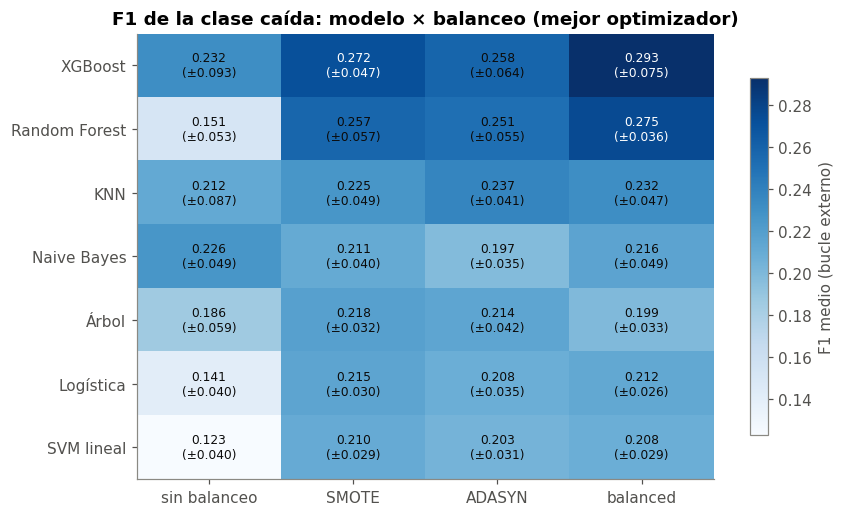

In [2]:
mejor_mb = clf.loc[clf.groupby(["modelo", "balanceo"])["f1_media"].idxmax()]
f1 = mejor_mb.pivot(index="modelo", columns="balanceo", values="f1_media")[BALANCEOS]
f1d = mejor_mb.pivot(index="modelo", columns="balanceo", values="f1_desv")[BALANCEOS]
f1 = f1.loc[f1.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 4.8))
im = ax.imshow(f1.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(4)); ax.set_xticklabels([BAL[b] for b in f1.columns])
ax.set_yticks(range(len(f1))); ax.set_yticklabels([NOMBRE[m] for m in f1.index])
ax.grid(False)
for i in range(f1.shape[0]):
    for j in range(f1.shape[1]):
        v, s = f1.iloc[i, j], f1d.loc[f1.index[i], f1.columns[j]]
        ax.text(j, i, f"{v:.3f}\n(±{s:.3f})", ha="center", va="center", fontsize=8,
                color="white" if v > np.nanmean(f1.values) + 0.05 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="F1 medio (bucle externo)")
ax.set_title("F1 de la clase caída: modelo × balanceo (mejor optimizador)")
plt.tight_layout()

In [3]:
# todas las métricas del bucle externo para los 28 modelo × balanceo (con su mejor optimizador)
def pm(df, m):
    return df[f"{m}_media"].round(3).astype(str) + " ± " + df[f"{m}_desv"].round(3).astype(str)
t = pd.DataFrame({"modelo": mejor_mb["modelo"].map(NOMBRE), "balanceo": mejor_mb["balanceo"].map(BAL),
                  "optimizador": mejor_mb["optimizador"].map(OPT), "F1": pm(mejor_mb, "f1"),
                  "precision": pm(mejor_mb, "precision"), "recall": pm(mejor_mb, "recall"),
                  "AUC": pm(mejor_mb, "auc"), "AP": pm(mejor_mb, "ap"), "accuracy": pm(mejor_mb, "accuracy"),
                  "_o": mejor_mb["f1_media"]})
t.sort_values("_o", ascending=False).drop(columns="_o").set_index(["modelo", "balanceo"])

optimizador             F1      precision  \
modelo        balanceo                                                 
XGBoost       balanced           Bayes  0.293 ± 0.075  0.225 ± 0.063   
Random Forest balanced        Genético  0.275 ± 0.036  0.198 ± 0.007   
XGBoost       SMOTE               Grid  0.272 ± 0.047   0.19 ± 0.042   
              ADASYN            Random  0.258 ± 0.064  0.175 ± 0.041   
Random Forest SMOTE             Random  0.257 ± 0.057  0.168 ± 0.041   
              ADASYN            Random  0.251 ± 0.055   0.163 ± 0.04   
KNN           ADASYN             Bayes  0.237 ± 0.041  0.157 ± 0.036   
              balanced            Grid  0.232 ± 0.047  0.157 ± 0.039   
XGBoost       sin balanceo      Random  0.232 ± 0.093  0.423 ± 0.111   
Naive Bayes   sin balanceo    Genético  0.226 ± 0.049  0.169 ± 0.042   
KNN           SMOTE           Genético  0.225 ± 0.049  0.138 ± 0.034   
Árbol         SMOTE           Genético  0.218 ± 0.032  0.143 ± 0.033   
Naive Bayes   balanced            Grid  0.216 ± 0.049  0.135 ± 0.036   
Logística     SMOTE             Random   0.215 ± 0.03  0.126 ± 0.019   
Árbol         ADASYN              Grid  0.214 ± 0.042   0.13 ± 0.028   
Logística     balanced          Random  0.212 ± 0.026  0.123 ± 0.016   
KNN           sin balanceo        Grid  0.212 ± 0.087  0.444 ± 0.105   
Naive Bayes   SMOTE             Random   0.211 ± 0.04  0.129 ± 0.027   
SVM lineal    SMOTE              Bayes   0.21 ± 0.029  0.122 ± 0.018   
              balanced            Grid  0.208 ± 0.029  0.121 ± 0.018   
Logística     ADASYN          Genético  0.208 ± 0.035   0.12 ± 0.022   
SVM lineal    ADASYN          Genético  0.203 ± 0.031   0.118 ± 0.02   
Árbol         balanced          Random  0.199 ± 0.033   0.129 ± 0.02   
Naive Bayes   ADASYN            Random  0.197 ± 0.035  0.117 ± 0.023   
Árbol         sin balanceo      Random  0.186 ± 0.059  0.231 ± 0.029   
Random Forest sin balanceo        Grid  0.151 ± 0.053   0.603 ± 0.16   
Logística     sin balanceo      Random   0.141 ± 0.04   0.517 ± 0.09   
SVM lineal    sin balanceo    Genético   0.123 ± 0.04  0.553 ± 0.099   

                                   recall            AUC             AP  \
modelo        balanceo                                                    
XGBoost       balanced      0.453 ± 0.168  0.857 ± 0.068  0.296 ± 0.089   
Random Forest balanced        0.47 ± 0.15  0.863 ± 0.052  0.281 ± 0.067   
XGBoost       SMOTE         0.489 ± 0.069  0.843 ± 0.067  0.257 ± 0.064   
              ADASYN        0.517 ± 0.171  0.845 ± 0.077  0.243 ± 0.074   
Random Forest SMOTE          0.58 ± 0.145  0.856 ± 0.064  0.248 ± 0.064   
              ADASYN        0.578 ± 0.153  0.857 ± 0.067   0.246 ± 0.06   
KNN           ADASYN        0.507 ± 0.091  0.758 ± 0.053  0.145 ± 0.031   
              balanced       0.46 ± 0.075  0.688 ± 0.042  0.169 ± 0.029   
XGBoost       sin balanceo  0.163 ± 0.077  0.836 ± 0.072  0.266 ± 0.084   
Naive Bayes   sin balanceo  0.358 ± 0.102  0.808 ± 0.041  0.153 ± 0.033   
KNN           SMOTE          0.632 ± 0.11   0.81 ± 0.067  0.194 ± 0.048   
Árbol         SMOTE         0.497 ± 0.088  0.722 ± 0.048  0.117 ± 0.018   
Naive Bayes   balanced      0.557 ± 0.123   0.807 ± 0.04  0.153 ± 0.033   
Logística     SMOTE         0.755 ± 0.118  0.854 ± 0.043   0.232 ± 0.05   
Árbol         ADASYN        0.626 ± 0.113  0.813 ± 0.058  0.158 ± 0.033   
Logística     balanced      0.763 ± 0.102  0.853 ± 0.047  0.228 ± 0.047   
KNN           sin balanceo  0.141 ± 0.065  0.689 ± 0.043   0.209 ± 0.05   
Naive Bayes   SMOTE         0.592 ± 0.105  0.801 ± 0.039  0.152 ± 0.033   
SVM lineal    SMOTE         0.758 ± 0.086  0.848 ± 0.047   0.22 ± 0.044   
              balanced      0.754 ± 0.088   0.847 ± 0.05  0.221 ± 0.043   
Logística     ADASYN        0.778 ± 0.098  0.852 ± 0.043  0.233 ± 0.057   
SVM lineal    ADASYN        0.765 ± 0.081  0.848 ± 0.044   0.22 ± 0.049   
Árbol         balanced       0.44 ± 0.095  0.667 ± 0.057  0.116 ± 

### Interpretación

- **El mejor es XGBoost con `balanced`** (F1 = 0,293 ± 0,075), seguido de Random Forest con `balanced` (0,275 ± 0,036) y XGBoost con SMOTE (0,272). Los ensambles de árboles vuelven a ganar, como en regresión.
- **Un F1 de ~0,3 es bajo en términos absolutos, pero hay que leerlo frente a la tasa base:** con 3,7 % de positivos, un clasificador al azar que marque el mismo 3,7 % tendría F1 ≈ 0,04, y uno que avise siempre, F1 ≈ 0,07. El AUC de ~0,86 dice que el modelo **ordena bien** los riesgos; el F1 bajo dice que separar con precisión las caídas reales es difícil, porque muchas no tienen señal en los datos del día anterior (cap. 14).
- **Sin balanceo** los modelos tienen alta precision (0,42–0,60) pero recall muy bajo (0,16 en XGBoost): casi nunca predicen caída, porque con 26:1 casi ningún caso supera 0,5 de probabilidad.
- La desviación entre folds es grande (±0,03 a ±0,09). Los folds con festivos tienen el doble de caídas y son más fáciles de detectar.

## ⚖️ 13.2 ¿Sirve el balanceo?

Se compara cada técnica contra **sin balanceo** dentro del mismo modelo y optimizador (28 pares por técnica). Además del F1, se miran el **recall** (cuántas caídas se detectan), la **precision** y el **AUC**. El AUC no depende del umbral, así que dice si el balanceo mejora la capacidad de **ordenar** los casos o solo mueve el umbral.

In [4]:
base = clf[clf["balanceo"] == "ninguno"].set_index(["modelo", "optimizador"])
filas = []
for b in ["smote", "adasyn", "balanced"]:
    otro = clf[clf["balanceo"] == b].set_index(["modelo", "optimizador"]).loc[base.index]
    for m in ["f1", "recall", "precision", "auc"]:
        d = otro[f"{m}_media"] - base[f"{m}_media"]
        w = stats.wilcoxon(d) if (d != 0).any() else None
        filas.append({"técnica": BAL[b], "métrica": m, "cambio medio": d.mean(), "mediana": d.median(),
                      "mejora en (de 28)": int((d > 0).sum()), "p Wilcoxon": w.pvalue if w else np.nan})
bal = pd.DataFrame(filas)
bal["p Holm"] = holm(bal["p Wilcoxon"].fillna(1))
bal.pivot(index="técnica", columns="métrica", values="cambio medio").round(3)

métrica,auc,f1,precision,recall
técnica,,,,
ADASYN,0.03,0.05,-0.32,0.49
SMOTE,0.03,0.05,-0.31,0.47
balanced,0.01,0.06,-0.30,0.43


In [5]:
bal.set_index(["técnica", "métrica"]).round(4)

cambio medio  mediana  mejora en (de 28)  p Wilcoxon  \
técnica  métrica                                                           
SMOTE    f1                 0.05     0.07                 24        0.00   
         recall             0.47     0.44                 28        0.00   
         precision         -0.31    -0.38                  0        0.00   
         auc                0.03     0.01                 18        0.00   
ADASYN   f1                 0.05     0.07                 24        0.00   
         recall             0.49     0.46                 28        0.00   
         precision         -0.32    -0.39                  0        0.00   
         auc                0.03     0.01                 18        0.01   
balanced f1                 0.06     0.07                 24        0.00   
         recall             0.43     0.36                 28        0.00   
         precision         -0.30    -0.36                  0        0.00   
         auc                0.01     0.01                 19        0.00   

                    p Holm  
técnica  métrica            
SMOTE    f1           0.00  
         recall       0.00  
         precision    0.00  
         auc          0.01  
ADASYN   f1           0.00  
         recall       0.00  
         precision    0.00  
         auc          0.01  
balanced f1           0.00  
         recall       0.00  
         precision    0.00  
         auc          0.01

Friedman entre balanceos: χ² = 30.3, p = 1.2e-06, CD = 0.89


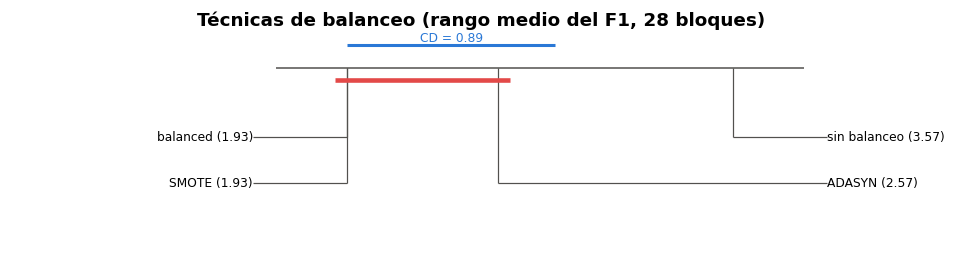

In [6]:
# Friedman entre las 4 técnicas de balanceo, con bloques = modelo × optimizador (28)
tabla = clf.pivot_table(index=["modelo", "optimizador"], columns="balanceo", values="f1_media")
fn_bal = friedman_nemenyi(-tabla.rename(columns=BAL))  # menos F1 = pérdida
print(f"Friedman entre balanceos: χ² = {fn_bal['chi2']:.1f}, p = {fn_bal['p']:.1e}, CD = {fn_bal['cd']:.2f}")
fig, ax = plt.subplots(figsize=(9, 2.6))
diagrama_cd(fn_bal["rangos"], fn_bal["cd"], ax, "Técnicas de balanceo (rango medio del F1, 28 bloques)")
plt.tight_layout()

### Interpretación

- **Las tres técnicas mejoran el F1 en 24 de 28 casos**, en +0,05 a +0,06 en promedio, todas significativas después de Holm. **Cómo** lo logran es muy claro:
  - el **recall sube muchísimo** (+0,43 a +0,49, en los 28 casos);
  - la **precision baja** casi lo mismo (−0,30 a −0,32, en los 28 casos);
  - el **AUC casi no cambia** (+0,01 a +0,03).
- O sea, **el balanceo no le enseña al modelo a distinguir mejor las caídas**: el AUC, que mide el orden, apenas se mueve. Lo que hace es **mover el umbral efectivo**, para que el modelo diga "caída" más veces. Con una clase de 3,7 %, el umbral por defecto de 0,5 es demasiado alto, y balancear equivale a bajarlo.
- **Friedman entre técnicas** (p = 1,2 × 10⁻⁶): `balanced` y SMOTE empatan en el mejor rango medio (1,93), ADASYN queda en 2,57 y sin balanceo en 3,57. La CD es 0,89, así que **las tres técnicas son significativamente mejores que no balancear** (por más de la CD) y **no se distinguen entre sí**.
- **Recomendación práctica:** `class_weight='balanced'`. Da el mismo resultado que SMOTE, no genera datos sintéticos, no duplica el tamaño de train (SMOTE y ADASYN duplican el tiempo de entrenamiento, cap. 11) y no depende de distancias en un espacio con variables muy colineales.

## 🎯 13.3 El mejor de cada modelo en test

Para cada uno de los 7 modelos se elige la combinación balanceo × optimizador con **mayor F1 en el bucle externo**, sin mirar test. En test se muestran la matriz de confusión, las curvas ROC y la tabla de métricas.

In [7]:
elegido = clf.loc[clf.groupby("modelo")["f1_media"].idxmax()].set_index("modelo")
res = {m: cargar("clf", m, elegido.loc[m, "balanceo"], elegido.loc[m, "optimizador"]) for m in MODELOS_CLF}
pred = {m: res[m]["pred_test"]["pred"].to_numpy() for m in MODELOS_CLF}
score = {m: res[m]["pred_test"]["score"].to_numpy() for m in MODELOS_CLF}
filas = []
for m in MODELOS_CLF:
    met = metricas_clf(y_te, pred[m], score[m], proba=m != "svm")
    filas.append({"modelo": NOMBRE[m], "balanceo": BAL[elegido.loc[m, "balanceo"]], "optimizador": OPT[elegido.loc[m, "optimizador"]],
                  "Accuracy": met["accuracy"], "Precision": met["precision"], "Recall": met["recall"], "F1-score": met["f1"],
                  "AUC": met["auc"], "AP": met["ap"], "F1 bucle externo": elegido.loc[m, "f1_media"]})
tabla_test = pd.DataFrame(filas).set_index("modelo").sort_values("F1-score", ascending=False)
orden_m = [{v: k for k, v in NOMBRE.items()}[n] for n in tabla_test.index]
tabla_test.round(3)

,balanceo,optimizador,Accuracy,Precision,Recall,F1-score,AUC,AP,F1 bucle externo
modelo,,,,,,,,,
XGBoost,balanced,Bayes,0.94,0.25,0.39,0.30,0.88,0.29,0.29
Random Forest,balanced,Genético,0.96,0.31,0.26,0.28,0.88,0.30,0.28
KNN,ADASYN,Bayes,0.89,0.15,0.54,0.24,0.77,0.13,0.24
Árbol,SMOTE,Genético,0.90,0.15,0.45,0.23,0.73,0.11,0.22
SVM lineal,SMOTE,Bayes,0.83,0.12,0.74,0.21,0.86,0.21,0.21
Logística,SMOTE,Random,0.83,0.12,0.73,0.21,0.87,0.22,0.21
Naive Bayes,sin balanceo,Genético,0.93,0.15,0.29,0.20,0.82,0.13,0.23


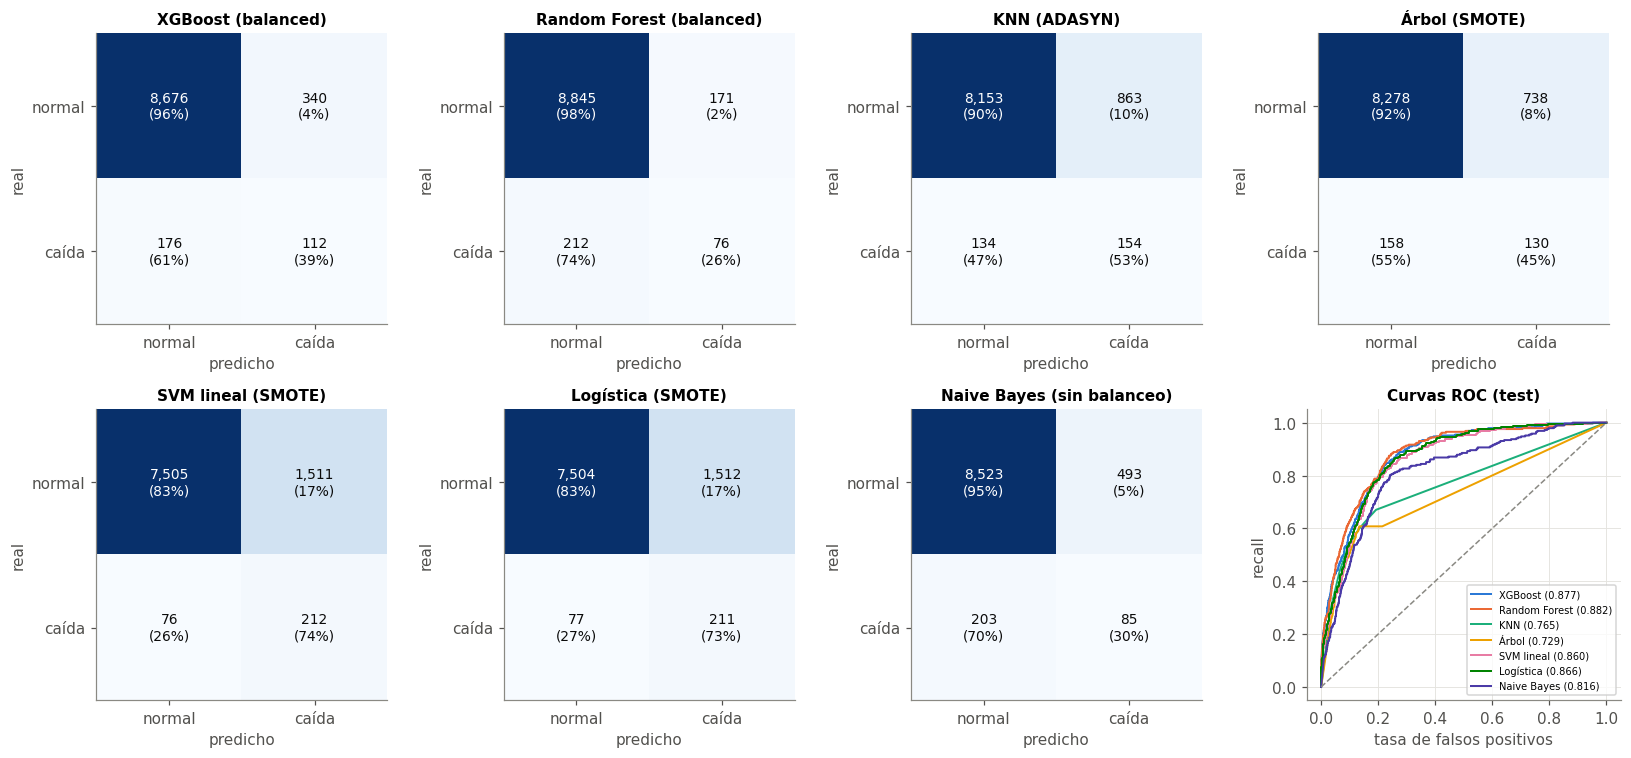

In [8]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
for ax, m in zip(axs.ravel(), orden_m):
    cm = confusion_matrix(y_te, pred[m])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({cm[i, j] / cm[i].sum():.0%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "#0b0b0b", fontsize=9)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["normal", "caída"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["normal", "caída"])
    ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(f"{NOMBRE[m]} ({BAL[elegido.loc[m, 'balanceo']]})", fontsize=10)
ax = axs.ravel()[-1]
for i, m in enumerate(orden_m):
    fpr, tpr, _ = roc_curve(y_te, score[m])
    ax.plot(fpr, tpr, color=PALETA[i], lw=1.3, label=f"{NOMBRE[m]} ({tabla_test.loc[NOMBRE[m], 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("recall"); ax.set_title("Curvas ROC (test)", fontsize=10)
ax.legend(fontsize=6.5, loc="lower right")
plt.tight_layout()

### Interpretación

- En test el orden se mantiene: **XGBoost (F1 0,30, AUC 0,88)** y **Random Forest (0,28, 0,88)** arriba; los demás entre 0,20 y 0,24. El F1 en test es muy parecido al del bucle externo (0,29 y 0,28), así que la validación anidada estimó bien.
- **Matrices de confusión**: XGBoost detecta el 39 % de las caídas (112 de 288) y de cada 4 alertas una es caída real (precision 0,25). Random Forest es más conservador (recall 0,26, precision 0,31). La logística y la SVM, con SMOTE, detectan casi 3 de cada 4 caídas (recall 0,73–0,74) pero con unas 7 falsas alarmas por cada acierto (precision 0,12).
- Cuál conviene depende del costo: si revisar un negocio es barato, sirve un modelo de recall alto; si cada alerta implica una visita, conviene XGBoost o Random Forest. Como su AUC es el más alto, **el umbral se puede mover** para elegir el punto de la curva ROC que convenga.
- **Accuracy** entre 0,83 y 0,96: confirma que no sirve aquí. Naive Bayes (0,93) tiene el peor F1, y un modelo que nunca avisa tendría 0,97.
- **ROC**: XGBoost, Random Forest, logística y SVM tienen AUC de 0,86–0,88; KNN (0,77) y el árbol (0,73) ordenan bastante peor.

## 🌡️ 13.4 Calibración de probabilidades

Una alerta útil no solo ordena bien: si dice "30 % de probabilidad de caída", en 30 de cada 100 casos así debería haber caída. Se evalúa con el **diagrama de confiabilidad**, el **Brier score** (error cuadrático de la probabilidad) y el **ECE** (10 bins de igual ancho).

**Recalibración.** Cada modelo elegido se reentrena con train **menos su última semana** (27 ago – 2 sep), y esa semana se usa para ajustar el **escalado de Platt** (una logística sobre el puntaje) y la **regresión isotónica** (una función escalonada creciente). Se evalúa en test. La SVM no da probabilidades, solo distancias al hiperplano, así que para ella Platt es la única forma de obtener una probabilidad.

In [9]:
corte_cal = train["fecha"].max() - pd.Timedelta(days=6)
ajuste, calib = train["fecha"] < corte_cal, train["fecha"] >= corte_cal
filas, curvas = [], {}
for m in orden_m:
    b = elegido.loc[m, "balanceo"]
    mod = crear_modelo("clf", m, res[m]["params_final"], b)
    ajustar(mod, train.loc[ajuste, X_COLS], y_tr[ajuste.values], "clf", m, b)
    s_cal, s_te = puntaje(mod, train.loc[calib, X_COLS]), puntaje(mod, test[X_COLS])
    versiones = {}
    if m != "svm":
        versiones["original"] = s_te
    for metodo in ["sigmoid", "isotonic"]:
        cal = CalibratedClassifierCV(mod, method=metodo, cv="prefit")
        cal.fit(train.loc[calib, X_COLS], y_tr[calib.values])
        versiones["Platt" if metodo == "sigmoid" else "isotónica"] = cal.predict_proba(test[X_COLS])[:, 1]
    for v, p in versiones.items():
        filas.append({"modelo": NOMBRE[m], "balanceo": BAL[b], "versión": v, "Brier": brier_score_loss(y_te, p),
                      "ECE": ece(y_te, p), "prob. media": p.mean(), "F1 (umbral 0,5)": f1_score(y_te, p >= 0.5)})
        curvas[(m, v)] = p
cal_tabla = pd.DataFrame(filas).set_index(["modelo", "versión"])
print(f"tasa real de caídas en test: {y_te.mean():.3f}")
cal_tabla.round(4)

tasa real de caídas en test: 0.031


balanceo  Brier  ECE  prob. media  \
modelo        versión                                            
XGBoost       original       balanced   0.04 0.04         0.07   
              Platt          balanced   0.03 0.01         0.03   
              isotónica      balanced   0.03 0.01         0.03   
Random Forest original       balanced   0.04 0.06         0.09   
              Platt          balanced   0.03 0.01         0.03   
              isotónica      balanced   0.03 0.01         0.03   
KNN           original         ADASYN   0.09 0.12         0.13   
              Platt            ADASYN   0.03 0.00         0.03   
              isotónica        ADASYN   0.03 0.01         0.03   
Árbol         original          SMOTE   0.08 0.09         0.10   
              Platt             SMOTE   0.03 0.01         0.03   
              isotónica         SMOTE   0.03 0.01         0.03   
SVM lineal    Platt             SMOTE   0.03 0.01         0.02   
              isotónica         SMOTE   0.03 0.01         0.03   
Logística     original          SMOTE   0.13 0.26         0.29   
              Platt             SMOTE   0.03 0.01         0.02   
              isotónica         SMOTE   0.03 0.01         0.03   
Naive Bayes   original   sin balanceo   0.06 0.07         0.07   
              Platt      sin balanceo   0.03 0.01         0.02   
              isotónica  sin balanceo   0.03 0.01         0.02   

                         F1 (umbral 0,5)  
modelo        versión                     
XGBoost       original              0.28  
              Platt                 0.24  
              isotónica             0.24  
Random Forest original              0.30  
              Platt                 0.20  
              isotónica             0.24  
KNN           original              0.21  
              Platt                 0.00  
              isotónica             0.00  
Árbol         original              0.23  
              Platt                 0.00  
              isotónica             0.00  
SVM lineal    Platt                 0.13  
              isotónica             0.12  
Logística     original              0.22  
              Platt                 0.14  
              isotónica             0.13  
Naive Bayes   original              0.20  
              Platt                 0.00  
              isotónica             0.00

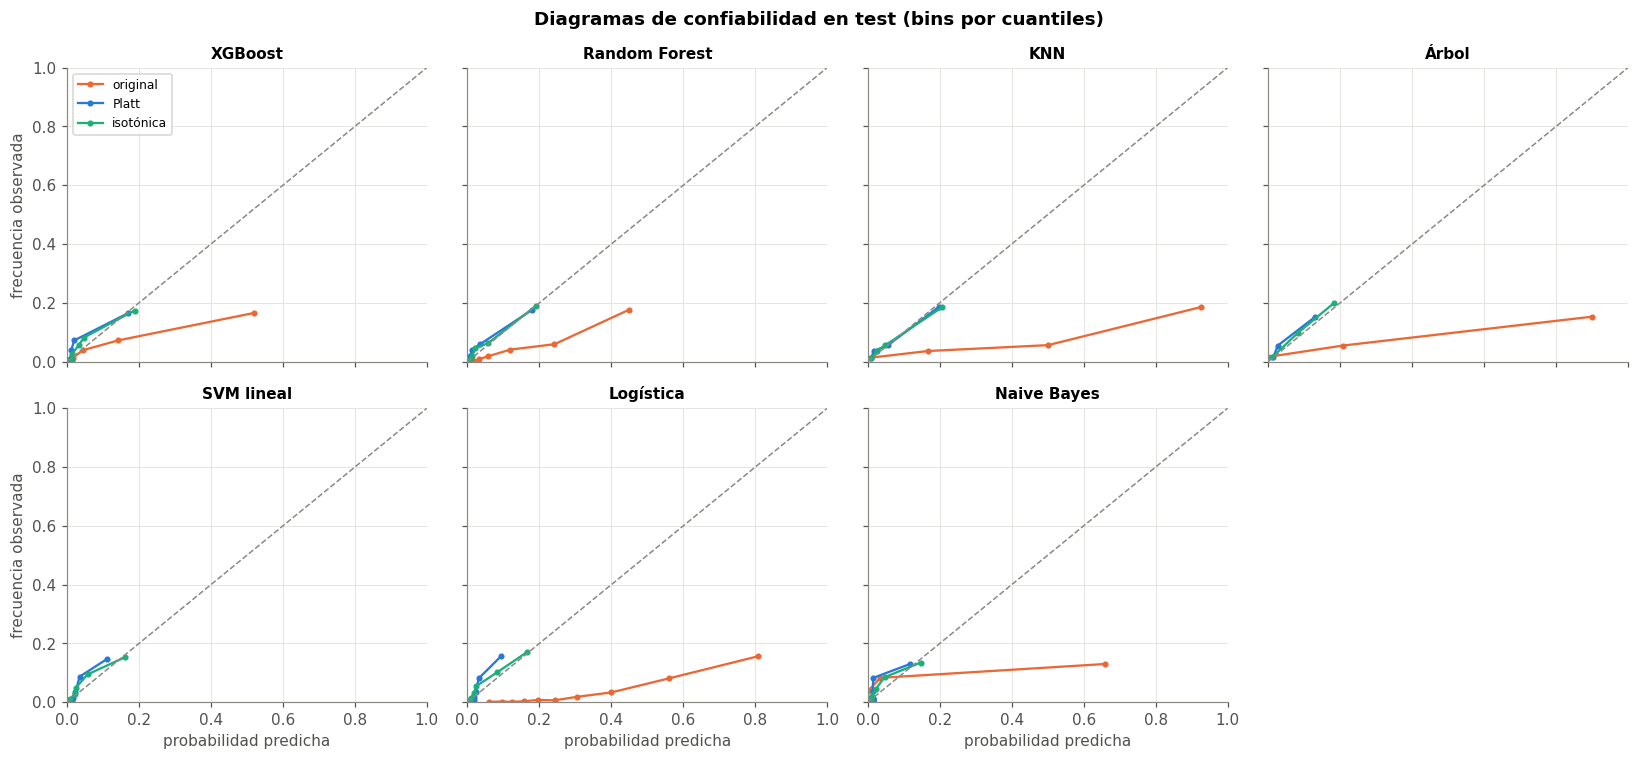

In [10]:
fig, axs = plt.subplots(2, 4, figsize=(15, 7), sharex=True, sharey=True)
for ax, m in zip(axs.ravel(), orden_m):
    for v, color in [("original", NARANJA), ("Platt", AZUL), ("isotónica", VERDE)]:
        if (m, v) not in curvas:
            continue
        fr, pm_ = calibration_curve(y_te, curvas[(m, v)], n_bins=10, strategy="quantile")
        ax.plot(pm_, fr, marker="o", ms=3, color=color, label=v)
    ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1)
    ax.set_title(NOMBRE[m], fontsize=10); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
axs.ravel()[0].legend(fontsize=8)
for ax in axs[:, 0]: ax.set_ylabel("frecuencia observada")
for ax in axs[-1]: ax.set_xlabel("probabilidad predicha")
axs.ravel()[-1].axis("off")
plt.suptitle("Diagramas de confiabilidad en test (bins por cuantiles)", fontweight="bold")
plt.tight_layout()

### Interpretación

- **Todos los modelos están mal calibrados en su versión original**, y siempre en el mismo sentido: **sobreestiman** la probabilidad de caída. La probabilidad media predicha va de 0,07 (XGBoost) a 0,29 (logística con SMOTE) cuando la tasa real es 0,03. Es la consecuencia directa del balanceo: el modelo aprendió con un 50 % de caídas (SMOTE) o con pesos que las igualan, así que sus probabilidades corresponden a ese mundo y no al real. El ECE va de 0,04 (XGBoost) a 0,26 (logística).
- **Platt e isotónica corrigen la calibración**: el ECE baja a ~0,01 y el Brier a 0,03 en todos los modelos, y la probabilidad media pasa a 0,02–0,03, igual a la real. En los diagramas, las curvas recalibradas quedan sobre la diagonal.
- **Pero el F1 con umbral 0,5 se desploma** después de recalibrar, en algunos modelos hasta 0. Es coherente: con probabilidades bien calibradas y una clase de 3 %, casi ningún caso supera 0,5. **Calibrar y elegir el umbral son dos decisiones distintas.** Para una alerta: (1) se recalibra para que la probabilidad sea interpretable ("este negocio tiene 30 % de probabilidad de caer mañana") y (2) se elige el umbral según el costo de las falsas alarmas (por ejemplo, alertar cuando P > 0,15).
- La SVM, que no da probabilidades, obtiene con Platt una probabilidad bien calibrada (ECE 0,01).

## 📐 13.5 Comparación estadística

### Etapa 1: Friedman (ómnibus) y Etapa 2: Nemenyi

Los bloques son los **28 días del bucle externo**: para cada día se calcula el F1 de cada modelo sobre los ~450 negocios de ese día (en promedio ~18 caídas por día). Se hace para los 7 modelos (con su mejor balanceo y optimizador) y para las 112 combinaciones.

In [11]:
def f1_diario(r):
    pv = r["pred_val"]
    sub = train.iloc[pv["fila"]]
    return pd.Series([f1_score(g["y"], g["p"], zero_division=0) for _, g in
                      pd.DataFrame({"y": sub["caida"].to_numpy(), "p": pv["pred"].to_numpy(), "f": sub["fecha"].to_numpy()}).groupby("f")])

f1_dia = pd.DataFrame({NOMBRE[m]: f1_diario(res[m]) for m in MODELOS_CLF})
fn7 = friedman_nemenyi(-f1_dia)
todas = {}
for _, fila in clf.iterrows():
    todas[f"{fila['modelo']}·{fila['balanceo']}·{fila['optimizador']}"] = f1_diario(cargar("clf", fila["modelo"], fila["balanceo"], fila["optimizador"]))
todas = pd.DataFrame(todas)
fn112 = friedman_nemenyi(-todas)
pd.DataFrame([{"comparación": "7 modelos", "k": 7, "bloques (días)": fn7["n"], "χ² Friedman": fn7["chi2"], "g.l.": 6, "p": fn7["p"], "CD Nemenyi": fn7["cd"]},
              {"comparación": "112 combinaciones", "k": 112, "bloques (días)": fn112["n"], "χ² Friedman": fn112["chi2"], "g.l.": 111, "p": fn112["p"], "CD Nemenyi": fn112["cd"]}]).set_index("comparación").round(4)

,k,bloques (días),χ² Friedman,g.l.,p,CD Nemenyi
comparación,,,,,,
7 modelos,7,28,26.04,6,0.00,1.70
112 combinaciones,112,28,609.83,111,0.00,37.77


las 10 mejores combinaciones por rango medio (de 112):
rf·balanced·random      25.43
xgb·balanced·bayes      27.25
xgb·balanced·random     28.14
rf·balanced·genetico    28.43
rf·balanced·bayes       28.71
xgb·balanced·grid       29.09
rf·balanced·grid        29.96
xgb·smote·bayes         31.05
xgb·balanced·genetico   31.61
rf·adasyn·random        33.57


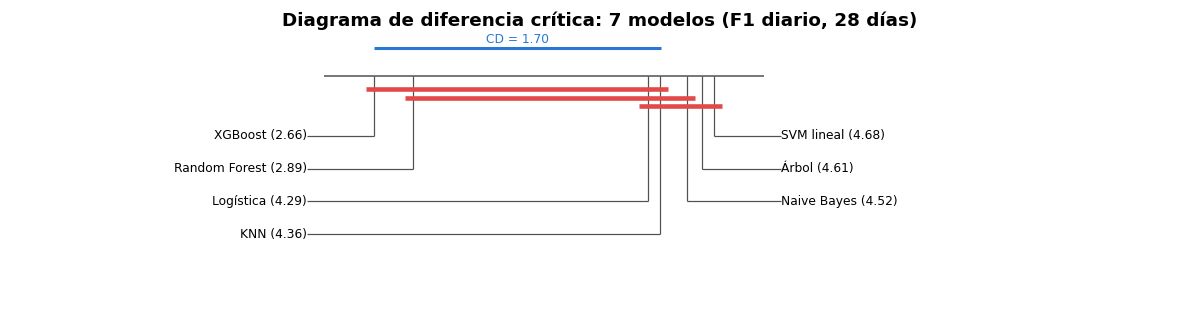

In [12]:
fig, ax = plt.subplots(figsize=(11, 3))
diagrama_cd(fn7["rangos"], fn7["cd"], ax, "Diagrama de diferencia crítica: 7 modelos (F1 diario, 28 días)")
plt.tight_layout()
top10 = fn112["rangos"].head(10)
print("las 10 mejores combinaciones por rango medio (de 112):")
print(top10.round(2).to_string())

### Interpretación

- **Friedman rechaza** para los 7 modelos (χ² = 26,0, p < 0,001) y para las 112 combinaciones (χ² = 610).
- **Nemenyi con los 7 modelos (CD = 1,70):** XGBoost (rango 2,66) y Random Forest (2,89) están arriba. La diferencia entre ellos (0,23) no es significativa. Contra los demás (4,29 a 4,68) la distancia de XGBoost es de 1,6 a 2,0: **significativa contra Naive Bayes, el árbol y la SVM** (más de la CD), justo en el límite contra KNN (1,70) y no significativa contra la logística (1,63). Con solo 28 bloques la prueba tiene poca potencia.
- **Con las 112 combinaciones** la CD es 37,8 rangos, tan grande que casi todo queda conectado. Es el costo de comparar 112 cosas con 28 bloques. Aun así, **las 7 mejores combinaciones son todas Random Forest o XGBoost con `balanced`**, y en el top 10 solo aparece otra técnica (SMOTE y ADASYN una vez cada una). El patrón es consistente aunque cada par por separado no sea significativo.

### Comparaciones dirigidas: DeLong entre los 3 mejores

La prueba de DeLong compara dos AUC calculadas sobre **las mismas observaciones** (test), teniendo en cuenta su correlación. Se aplica solo a los 3 mejores modelos del ranking de Friedman (3 pares), con corrección de **Holm** y de **Benjamini-Hochberg**. El intervalo de la diferencia de AUC es un **bootstrap por negocios** (1 000 réplicas, percentil). El tamaño del efecto es la **delta de Cliff** sobre el F1 diario del bucle externo.

In [13]:
from statsmodels.stats.multitest import multipletests
top3 = [{v: k for k, v in NOMBRE.items()}[n] for n in fn7["rangos"].index[:3]]
neg = test["negocio"].to_numpy(); grupos = np.unique(neg)
filas_neg = {g: np.where(neg == g)[0] for g in grupos}
rng = np.random.default_rng(SEED)
filas = []
for a, b in combinations(top3, 2):
    auc_a, auc_b, z, p = delong(y_te, score[a], score[b])
    difs = []
    for _ in range(1000):
        idx = np.concatenate([filas_neg[g] for g in rng.choice(grupos, len(grupos))])
        if y_te[idx].min() == y_te[idx].max():
            continue
        difs.append(delong(y_te[idx], score[a][idx], score[b][idx])[0] - delong(y_te[idx], score[a][idx], score[b][idx])[1])
    lo, hi = np.percentile(difs, [2.5, 97.5])
    dc = cliff_delta(f1_dia[NOMBRE[a]], f1_dia[NOMBRE[b]])
    filas.append({"A": NOMBRE[a], "B": NOMBRE[b], "AUC A": auc_a, "AUC B": auc_b, "diferencia": auc_a - auc_b,
                  "IC 95 % bootstrap": f"[{lo:.3f}, {hi:.3f}]", "z DeLong": z, "p crudo": p,
                  "delta de Cliff (F1 diario)": dc, "magnitud": magnitud_cliff(dc)})
dl = pd.DataFrame(filas)
dl["p Holm"] = holm(dl["p crudo"]); dl["p BH"] = multipletests(dl["p crudo"], method="fdr_bh")[1]
dl.round(4)

,A,B,AUC A,AUC B,diferencia,IC 95 % bootstrap,z DeLong,p crudo,delta de Cliff (F1 diario),magnitud,p Holm,p BH
0,XGBoost,Random Forest,0.88,0.88,-0.01,"[-0.015, 0.004]",-1.10,0.27,0.05,despreciable,0.27,0.27
1,XGBoost,Logística,0.88,0.87,0.01,"[-0.005, 0.025]",1.51,0.13,0.36,mediano,0.26,0.20
2,Random Forest,Logística,0.88,0.87,0.02,"[0.003, 0.027]",2.56,0.01,0.37,mediano,0.03,0.03


In [14]:
# intervalos BCa por negocios para el AUC y el F1 de test de los 3 mejores
from sklearn.metrics import roc_auc_score
filas = []
for m in top3:
    auc_f = lambda i, m=m: roc_auc_score(y_te[i], score[m][i]) if y_te[i].min() < y_te[i].max() else np.nan
    f1_f = lambda i, m=m: f1_score(y_te[i], pred[m][i], zero_division=0)
    lo, hi = ic_bca_negocios(neg, auc_f, reps=500)
    lo2, hi2 = ic_bca_negocios(neg, f1_f, reps=500)
    filas.append({"modelo": NOMBRE[m], "AUC": roc_auc_score(y_te, score[m]), "IC 95 % AUC (BCa)": f"[{lo:.3f}, {hi:.3f}]",
                  "F1": f1_score(y_te, pred[m]), "IC 95 % F1 (BCa)": f"[{lo2:.3f}, {hi2:.3f}]"})
pd.DataFrame(filas).set_index("modelo").round(3)

,AUC,IC 95 % AUC (BCa),F1,IC 95 % F1 (BCa)
modelo,,,,
XGBoost,0.88,"[0.853, 0.899]",0.30,"[0.241, 0.372]"
Random Forest,0.88,"[0.862, 0.904]",0.28,"[0.211, 0.376]"
Logística,0.87,"[0.843, 0.886]",0.21,"[0.177, 0.246]"


### Interpretación

- **DeLong entre los 3 mejores del ranking** (XGBoost, Random Forest, logística):
  - XGBoost contra Random Forest: AUC prácticamente igual (0,88), diferencia ≈ −0,01, **no significativa** (p = 0,27). El intervalo bootstrap contiene el 0. La delta de Cliff sobre el F1 diario es **despreciable** (0,05).
  - XGBoost contra logística: diferencia de AUC +0,01, no significativa (p Holm = 0,26), pero el efecto sobre el F1 diario es **mediano** (Cliff 0,36). La logística **ordena** casi igual de bien, pero su punto de corte con SMOTE da peor F1.
  - Random Forest contra logística: diferencia +0,02, **significativa** (p Holm = 0,03; IC [0,003; 0,027]) y efecto mediano en F1 (Cliff 0,37).
- **Intervalos BCa en test:** el AUC de los tres está entre 0,84 y 0,90 con intervalos que se solapan. El F1 de XGBoost [0,24; 0,37] y el de Random Forest [0,21; 0,38] se solapan casi por completo, y los dos quedan por encima del de la logística [0,18; 0,25].
- **Conclusión de la secuencia completa (Friedman → Nemenyi → DeLong → Cliff):** los ensambles de árboles balanceados son el mejor grupo. Entre XGBoost y Random Forest **no hay diferencia demostrable**.

## 🎲 13.6 Sensibilidad a la semilla

Random Forest y XGBoost (con su balanceo e hiperparámetros elegidos), reentrenados con 5 semillas. Se compara la variación del F1 y del AUC en test con las diferencias entre modelos.

In [15]:
filas = []
for m in ["rf", "xgb"]:
    b = elegido.loc[m, "balanceo"]
    for s in [42, 7, 2026, 11, 123]:
        mod = crear_modelo("clf", m, res[m]["params_final"], b, semilla=s)
        ajustar(mod, train[X_COLS], y_tr, "clf", m, b)
        filas.append({"modelo": NOMBRE[m], "semilla": s, "F1 test": f1_score(y_te, mod.predict(test[X_COLS])),
                      "AUC test": roc_auc_score(y_te, puntaje(mod, test[X_COLS]))})
sem = pd.DataFrame(filas)
sem.groupby("modelo")[["F1 test", "AUC test"]].agg(["mean", "std", "min", "max"]).round(4)

F1 test                AUC test               
                 mean  std  min  max     mean  std  min  max
modelo                                                      
Random Forest    0.29 0.01 0.28 0.32     0.88 0.00 0.88 0.89
XGBoost          0.30 0.01 0.28 0.30     0.88 0.00 0.88 0.88

### Interpretación

- Por semilla, el F1 en test varía con una desviación de ~0,01 (rango 0,28–0,32 en Random Forest) y el AUC con menos de 0,005. La variación del F1 por semilla es **comparable** a la diferencia entre XGBoost y Random Forest (0,30 contra 0,29), otra razón para no declarar un ganador entre los dos. En cambio, es mucho menor que la distancia a los demás modelos (≥ 0,06).